*Robot Motion Control · Chapter 2 — Independent-Joint Control*

# 2.1 The Single-Joint Model: Actuator, Gearing and Disturbances

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/RMC/02-independent-joint-control/2.1-the-single-joint-model.ipynb)

Almost every industrial robot is controlled, at the lowest level, one joint at a time: each joint has its own motor,
its own encoder and its own feedback loop, and no joint "knows" what the others are doing. This is a bold
simplification, because the joints of a manipulator are strongly coupled through its dynamics. This notebook builds the
model that justifies the simplification. We start from a DC motor, add a gearbox, and obtain a single second-order system
with an *effective inertia* and *effective damping*; everything that the model leaves out — gravity, the motion of the
other joints, the change of the link inertia with configuration — is then treated as a **disturbance** whose size
shrinks as the gear ratio grows. We derive the planar two-link arm to see exactly what those disturbances are, and we
measure them on a real UR5e and Franka Panda in MuJoCo.

| | |
|:--|:--|
| **Primary reading** | Craig, *Introduction to Robotics*, Ch. 9 *Linear Control of Manipulators* |
| **Parallel reading** | Spong, Hutchinson & Vidyasagar, 2nd ed., Ch. 8 *Independent Joint Control* · Siciliano et al., Ch. 8 *Motion Control* · Lynch & Park, Ch. 11 *Robot Control* · Corke, *RVC* Ch. 9 *Dynamics and Control* |
| **Lectures** | [Sapienza *Robotics 2* (A. De Luca), lecture playlist](https://www.youtube.com/playlist?list=PLAQopGWlIcya6LnIF83QlJTqvpYmJXnDm) · [NPTEL *Mechanics and Control of Robotic Manipulators* (IIT Palakkad)](https://nptel.ac.in/courses/112106304) · Prof. G. C. Nandi, playlist 2, *Mathematical Foundation of Robotics — Execution Level …* (IIIT Allahabad; by title) |
| **Prerequisites** | MFoR Chapter 6 (manipulator dynamics: the Lagrangian form $M\ddot q + C\dot q + g = \tau$ is re-derived for the planar 2R arm here) · Chapter 1 of this course (second-order systems; recalled where needed) |
| **Study time** | about 3 hours |

## Learning objectives

1. Write the electrical and mechanical equations of a DC-motor-driven joint and reduce them to a second-order model with an effective inertia and damping.
2. Derive the **effective inertia** $J_{\mathrm{eff}} = J_m + J_l/r^2$ (motor side) and its load-side equivalent, and explain why industrial arms use large gear ratios (including the inertia-matching ratio $r^\star=\sqrt{J_l/J_m}$).
3. State the transfer function of a single joint, and identify its mechanical time constant and its integrator.
4. Derive the equations of motion $M(q)\ddot q + C(q,\dot q)\dot q + g(q)=\tau$ of the planar 2R arm and show that, seen from one joint, the other joints and gravity act as disturbances.
5. Quantify how the configuration-dependent inertia, the inertial coupling, the Coriolis terms and gravity are reduced by the gear ratio, and compute the ratio needed for a given tolerance.
6. Verify the hand-derived model against MuJoCo, and read the range of the effective inertia of every joint of a real UR5e and Panda.

## Contents

1. [Why control one joint at a time?](#1.-Why-control-one-joint-at-a-time?)
2. [The actuator: a DC motor](#2.-The-actuator:-a-DC-motor)
3. [Gearing: effective inertia and damping](#3.-Gearing:-effective-inertia-and-damping)
4. [The single-joint plant](#4.-The-single-joint-plant)
5. [From one joint to many: the planar 2R arm](#5.-From-one-joint-to-many:-the-planar-2R-arm)
6. [Coupling and gravity as disturbances](#6.-Coupling-and-gravity-as-disturbances)
7. [How much does the inertia change? The role of the gear ratio](#7.-How-much-does-the-inertia-change?-The-role-of-the-gear-ratio)
8. [Checking the model against MuJoCo](#8.-Checking-the-model-against-MuJoCo)
9. [Real robots: the inertia of every joint of a UR5e and a Panda](#9.-Real-robots:-the-inertia-of-every-joint-of-a-UR5e-and-a-Panda)
10. [Worked examples](#10.-Worked-examples)
11. [Summary, common mistakes and exercises](#11.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import joint_control as jc
from rgkit import mujoco_utils as mju, robots
import mujoco

## 1. Why control one joint at a time?

A serial manipulator with $n$ joints has $n$ actuators. The **independent-joint** (or *decentralised*) approach gives
every actuator its own controller, which sees only the angle and velocity of *its own* joint and the desired angle and
velocity for that joint. The controller of joint $i$ is blind to the inertia of the other links, to their motion and to
the gravity load. This is how most industrial controllers are organised (Craig, Ch. 9; Spong et al., Ch. 8), and the rest of
this chapter is about what such a scheme can and cannot do.

The figure shows one such servo loop. The reference $\theta_d$ and the measured angle $\theta$ are compared, a
controller (here a proportional–derivative law, to be studied in Notebook 2.2) turns the error into a command, a
power amplifier with its own **current loop** turns the command into a motor torque, and the motor drives the link
through a gearbox. Everything that the link does besides rotating — gravity, forces from the other links — enters as a
disturbance torque at the load.

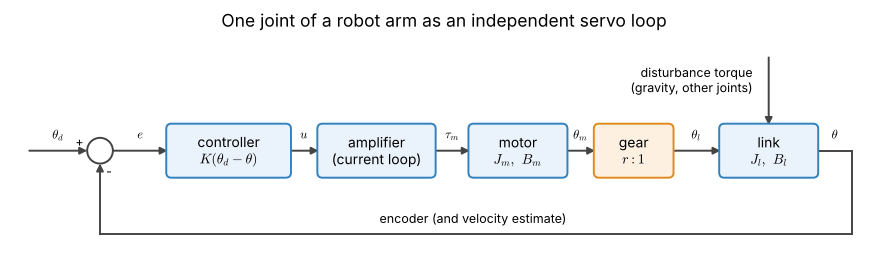

In [2]:
fig, ax = plt.subplots(figsize=(11.2, 3.3))
s = jc.bd_sum(ax, 0.9, 0.0)
ctl = jc.bd_box(ax, 2.9, 0.0, "controller\n$K(\\theta_d-\\theta)$", w=1.9)
amp = jc.bd_box(ax, 5.2, 0.0, "amplifier\n(current loop)", w=1.8)
mot = jc.bd_box(ax, 7.4, 0.0, "motor\n$J_m,\\ B_m$", w=1.5)
gear = jc.bd_box(ax, 9.2, 0.0, "gear\n$r:1$", w=1.2, fc="#fdf0e0", ec="#e08a1e")
link = jc.bd_box(ax, 11.3, 0.0, "link\n$J_l,\\ B_l$", w=1.5)
jc.bd_arrow(ax, [(-0.2, 0), s["l"]], r"$\theta_d$")
jc.bd_arrow(ax, [s["r"], ctl["l"]], r"$e$")
jc.bd_arrow(ax, [ctl["r"], amp["l"]], r"$u$")
jc.bd_arrow(ax, [amp["r"], mot["l"]], r"$\tau_m$")
jc.bd_arrow(ax, [mot["r"], gear["l"]], r"$\theta_m$")
jc.bd_arrow(ax, [gear["r"], link["l"]], r"$\theta_l$")
jc.bd_arrow(ax, [link["r"], (12.6, 0), (12.6, -1.3), (0.9, -1.3), s["b"]], r"$\theta$", label_at=0)
ax.text(6.7, -1.17, "encoder (and velocity estimate)", ha="center", va="bottom", fontsize=9)
jc.bd_arrow(ax, [(11.3, 1.45), link["t"]])
ax.text(11.05, 1.1, "disturbance torque\n(gravity, other joints)", ha="right", va="center", fontsize=9)
ax.set_xlim(-0.5, 13.0); ax.set_ylim(-1.7, 1.8); ax.set_aspect("equal"); ax.set_axis_off()
ax.set_title("One joint of a robot arm as an independent servo loop")
plt.show()

The simplification works only if the plant seen by each loop is *approximately* a fixed second-order system and the
disturbances are *small compared with what the loop can reject*. Gearing is what makes that true — and the following
sections show precisely how.

## 2. The actuator: a DC motor

Most robot joints are driven by permanent-magnet DC motors (brushed or, more often today, brushless motors driven so
that they behave in the same way). The armature circuit and the shaft obey

$$
v = R\,i + L\frac{di}{dt} + K_b\,\omega_m,
\qquad
\tau_m = K_t\,i,
\qquad
J_m\dot\omega_m + B_m\,\omega_m = \tau_m - \tau_g .
$$

Here $v$ is the armature voltage, $i$ the current, $R$ and $L$ the armature resistance and inductance, $\omega_m=\dot\theta_m$
the shaft speed, $K_t$ the **torque constant** (N·m/A) and $K_b$ the **back-EMF constant** (V·s/rad). In SI units
$K_t$ and $K_b$ are numerically equal, because both express the same energy conversion. $J_m$ and $B_m$ are the rotor
inertia and viscous friction, and $\tau_g$ is the torque that the shaft delivers to the gearbox.

**The electrical time constant is negligible.** The ratio $L/R$ is typically of the order of a millisecond, whereas the
mechanical time constant is tens of milliseconds. Setting $L\,di/dt\approx0$ gives $i=(v-K_b\omega_m)/R$ and therefore

$$
\tau_m = \frac{K_t}{R}\,v - \frac{K_tK_b}{R}\,\omega_m .
$$

Seen from the shaft, a voltage-driven motor is a *torque source* $\tfrac{K_t}{R}v$ with an additional **electrical
damping** $K_tK_b/R$ that the back-EMF produces. Substituting into the shaft equation yields the familiar model

$$
J_m\ddot\theta_m + \Big(B_m + \frac{K_tK_b}{R}\Big)\dot\theta_m = \frac{K_t}{R}\,v - \tau_g,
\qquad
\frac{\Theta_m(s)}{V(s)} = \frac{K_t/R}{s\,\big(J_m s + B_m + K_tK_b/R\big)} \quad(\tau_g=0).
$$

**Current (torque) drive.** A servo amplifier usually closes a fast loop around the *current*, so that the motor
torque follows the command, $\tau_m\approx K_t\,i_{\rm cmd}$, regardless of the back-EMF. The electrical damping then
disappears and the controller output can be regarded directly as a torque. The rest of this chapter uses this torque
input, and the amplifier appears again as the innermost loop of the industrial architecture in Notebook 2.4.

The cell below compares the full third-order model (with $L$) against the reduced second-order model for a motor with
$R=1.2\,\Omega$, $L=0.6$ mH, $K_t=K_b=0.05$, $J_m=1.2\times10^{-4}$ kg·m², $B_m=2\times10^{-5}$ N·m·s/rad, to show
how little is lost by neglecting $L$.

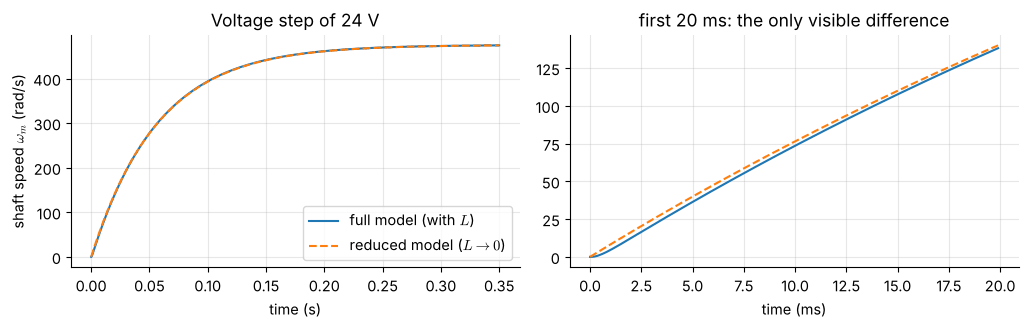

electrical time constant L/R = 0.50 ms,   mechanical time constant J/(B+KtKb/R) = 57.1 ms
steady-state speed: full 474.5 rad/s, reduced 475.4 rad/s;  largest deviation of the two curves 3.92 rad/s


In [3]:
Kt = Kb = 0.05; R = 1.2; L = 0.6e-3; Jm = 1.2e-4; Bm = 2e-5; V = 24.0

# Full model: states [i, omega].  L di/dt = V - R i - Kb w ;  Jm dw/dt = Kt i - Bm w
A_full = np.array([[-R / L, -Kb / L], [Kt / Jm, -Bm / Jm]]); b_full = np.array([1 / L, 0.0])
t = np.linspace(0, 0.35, 3501); dt = t[1] - t[0]
x = np.zeros(2); w_full = []
for _ in t:                                                    # exact (matrix-exponential) stepping
    w_full.append(x[1])
    x = x + dt * (A_full @ x + b_full * V)                      # tiny step: forward Euler is fine here
w_full = np.array(w_full)

# Reduced model (L = 0): first-order in speed, with electrical damping Kt*Kb/R
B_eff_v = Bm + Kt * Kb / R
tau_mech = Jm / B_eff_v
w_inf = (Kt / R) * V / B_eff_v
w_red = w_inf * (1 - np.exp(-t / tau_mech))

fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.4))
ax[0].plot(t, w_full, label="full model (with $L$)"); ax[0].plot(t, w_red, "--", label="reduced model ($L\\to0$)")
ax[0].set(xlabel="time (s)", ylabel=r"shaft speed $\omega_m$ (rad/s)", title="Voltage step of 24 V"); ax[0].legend()
ax[1].plot(t[:200] * 1e3, w_full[:200], label="full"); ax[1].plot(t[:200] * 1e3, w_red[:200], "--", label="reduced")
ax[1].set(xlabel="time (ms)", title="first 20 ms: the only visible difference")
plt.tight_layout(); plt.show()
print(f"electrical time constant L/R = {L / R * 1e3:.2f} ms,   mechanical time constant J/(B+KtKb/R) = {tau_mech * 1e3:.1f} ms")
print(f"steady-state speed: full {w_full[-1]:.1f} rad/s, reduced {w_inf:.1f} rad/s;  largest deviation of the two curves {np.abs(w_full - w_red).max():.2f} rad/s")

## 3. Gearing: effective inertia and damping

A robot joint needs high torque at low speed, whereas a compact motor delivers low torque at high speed. A gearbox with
**reduction ratio** $r>1$ resolves the mismatch. We define

$$
\theta_m = r\,\theta_l,\qquad \dot\theta_m = r\,\dot\theta_l,\qquad \tau_l = r\,\tau_g \quad(\text{ideal, lossless gear}),
$$

where subscript $l$ refers to the load (the joint). The torque relation follows from conservation of power,
$\tau_g\dot\theta_m=\tau_l\dot\theta_l$. (Craig writes $\eta$ for the ratio; here $r$ is used, as in most modern texts.)
The rotor and the load obey

$$
J_m\ddot\theta_m + B_m\dot\theta_m = \tau_m - \tau_g,
\qquad
J_l\ddot\theta_l + B_l\dot\theta_l + \tau_{\rm ext} = \tau_l = r\,\tau_g ,
$$

with $\tau_{\rm ext}$ the external (gravity and coupling) torque at the joint.

**Motor side.** Eliminate $\tau_g=\tau_l/r$ and write $\theta_l=\theta_m/r$ in the load equation. Then
$\tau_g = (J_l/r^2)\ddot\theta_m + (B_l/r^2)\dot\theta_m + \tau_{\rm ext}/r$, and the shaft equation becomes

$$
\boxed{\;\Big(J_m + \frac{J_l}{r^2}\Big)\ddot\theta_m + \Big(B_m + \frac{B_l}{r^2}\Big)\dot\theta_m + \frac{\tau_{\rm ext}}{r} = \tau_m\;}
\qquad\Longrightarrow\qquad
J_{\rm eff}=J_m+\frac{J_l}{r^2},\quad B_{\rm eff}=B_m+\frac{B_l}{r^2}.
$$

**Load side.** Multiplying by $r^2$ and using $\theta_m=r\theta_l$,

$$
\big(J_l + r^2J_m\big)\ddot\theta_l + \big(B_l + r^2B_m\big)\dot\theta_l + \tau_{\rm ext} = r\,\tau_m ,
$$

so the rotor inertia appears at the joint multiplied by $r^2$ — the **reflected rotor inertia**. This is exactly what the
`armature` attribute of a MuJoCo joint represents (it is added to the diagonal of the mass matrix; Section 9). Both
descriptions are the same system: $J_l+r^2J_m = r^2 J_{\rm eff}$.

Two consequences matter for control.

1. For large $r$ the rotor term dominates, $J_{\rm eff}\to J_m$: the **load inertia, which varies with configuration and
   payload, is hidden behind the constant rotor inertia** and the plant is nearly constant.
2. All disturbances at the load are divided by $r$ when seen by the motor (the term $\tau_{\rm ext}/r$).

**Inertia matching.** How large should $r$ be? With a motor torque $\tau_m$ the load acceleration is
$\ddot\theta_l=r\tau_m/(r^2J_m+J_l)$. Setting the derivative with respect to $r$ to zero gives $r^2J_m=J_l$:

$$
r^\star = \sqrt{J_l/J_m}\qquad(\text{the reflected load inertia equals the rotor inertia}),
\qquad
\ddot\theta_{l,\max} = \frac{r^\star\tau_m}{2J_l}.
$$

Beyond $r^\star$ the rotor inertia, multiplied by $r^2$, makes the joint sluggish; below it the motor is under-utilised.
Real arms use ratios at or somewhat above $r^\star$ (from about 50 to over 100 for harmonic drives), which is also what
makes the plant nearly constant. The figure uses a motor with $J_m=1.2\times10^{-4}$ kg·m² driving $J_l=0.45$ kg·m².

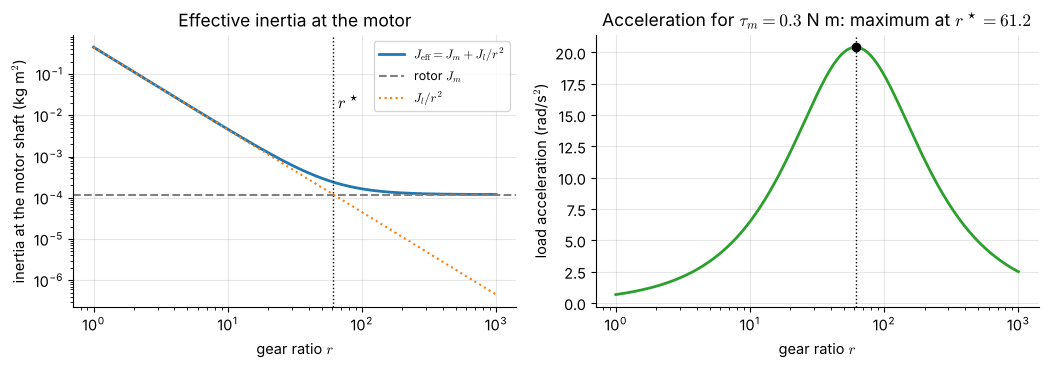

r* = sqrt(Jl/Jm) = 61.237; brute-force maximiser of the acceleration = 61.237; peak acceleration 20.41 rad/s^2


In [4]:
Jm_, Jl_, tau_m_ = 1.2e-4, 0.45, 0.3
r = np.logspace(0, 3, 400)
J_motor = jc.effective_inertia(Jm_, Jl_, r)           # seen at the motor shaft
acc = r * tau_m_ / jc.reflected_to_load(Jm_, Jl_, r)  # load acceleration for a motor torque of 0.3 N m
r_star = np.sqrt(Jl_ / Jm_)

fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.8))
ax[0].loglog(r, J_motor, "C0", lw=2, label=r"$J_{\rm eff}=J_m+J_l/r^2$")
ax[0].axhline(Jm_, color="grey", ls="--", label=r"rotor $J_m$"); ax[0].loglog(r, Jl_ / r**2, "C1:", label=r"$J_l/r^2$")
ax[0].axvline(r_star, color="k", ls=":", lw=1); ax[0].text(r_star * 1.08, J_motor.max() / 30, r"$r^\star$", fontsize=12)
ax[0].set(xlabel="gear ratio $r$", ylabel=r"inertia at the motor shaft (kg m$^2$)", title="Effective inertia at the motor")
ax[0].legend(fontsize=9)
ax[1].semilogx(r, acc, "C2", lw=2); ax[1].axvline(r_star, color="k", ls=":", lw=1)
ax[1].plot([r_star], [r_star * tau_m_ / (2 * Jl_)], "ko")
ax[1].set(xlabel="gear ratio $r$", ylabel=r"load acceleration (rad/s$^2$)", title=fr"Acceleration for $\tau_m={tau_m_}$ N m: maximum at $r^\star={r_star:.1f}$")
plt.tight_layout(); plt.show()

r_grid = np.linspace(1, 500, 500001)
r_brute = r_grid[np.argmax(r_grid * tau_m_ / jc.reflected_to_load(Jm_, Jl_, r_grid))]
print(f"r* = sqrt(Jl/Jm) = {r_star:.3f}; brute-force maximiser of the acceleration = {r_brute:.3f}; "
      f"peak acceleration {r_star * tau_m_ / (2 * Jl_):.2f} rad/s^2")
assert abs(r_brute - r_star) < 1e-2

## 4. The single-joint plant

Collect the motor-side model with a torque input $\tau_m$ and a disturbance $d=\tau_{\rm ext}/r$:

$$
J_{\rm eff}\ddot\theta_m + B_{\rm eff}\dot\theta_m = \tau_m - d .
$$

With $d=0$ the transfer function from torque to angle is

$$
G(s)=\frac{\Theta_m(s)}{T_m(s)}=\frac{1}{s\,(J_{\rm eff}s+B_{\rm eff})}=\frac{1/B_{\rm eff}}{s\,(T_{\rm mech}s+1)},
\qquad T_{\rm mech}=\frac{J_{\rm eff}}{B_{\rm eff}} .
$$

The plant has a **pole at the origin** (an integrator: the angle keeps growing under a constant velocity) and a stable
pole at $-1/T_{\rm mech}$. It is *not* stable by itself in the sense of position — apply a constant torque and the
velocity settles at $\tau/B_{\rm eff}$ while the angle grows without bound. A feedback loop must supply the restoring
action; this is the subject of Notebook 2.2. The figure shows the open-loop response for two values of $J_{\rm eff}$,
which is what a configuration change does to a joint whose load inertia is not hidden by the gearing.

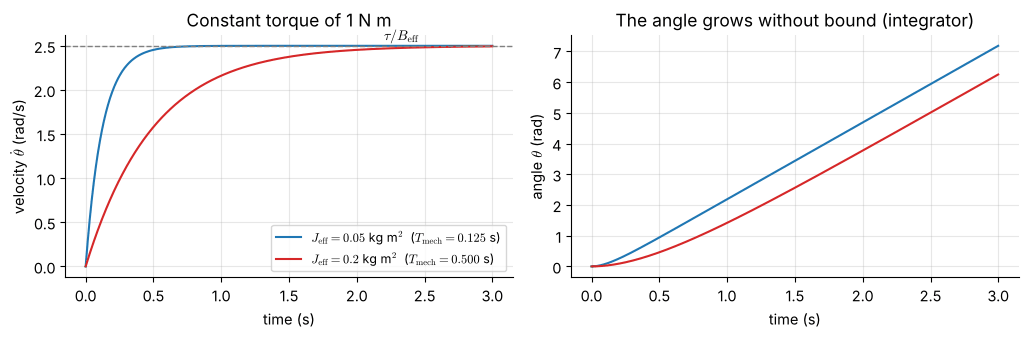

In [5]:
B_ = 0.4
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.5))
for J_, c in ((0.05, "C0"), (0.20, "C3")):
    res = jc.simulate(jc.Joint(J_, B_), lambda q, qd, a, b, c_: 1.0, np.zeros(1), 3.0, 1e-3)   # constant 1 N m torque
    ax[0].plot(res.t, res.qd, c, label=fr"$J_{{\rm eff}}={J_}$ kg m$^2$  ($T_{{\rm mech}}={J_/B_:.3f}$ s)")
    ax[1].plot(res.t, res.q, c)
    assert abs(res.qd[-1] - 1.0 / B_) < 5e-3 * (1.0 / B_)      # 3 s is six time constants for the heavier joint
ax[0].axhline(1.0 / B_, color="grey", ls="--", lw=1); ax[0].text(2.2, 1.0 / B_ + 0.06, r"$\tau/B_{\rm eff}$", fontsize=10)
ax[0].set(xlabel="time (s)", ylabel=r"velocity $\dot\theta$ (rad/s)", title="Constant torque of 1 N m"); ax[0].legend(fontsize=9)
ax[1].set(xlabel="time (s)", ylabel=r"angle $\theta$ (rad)", title="The angle grows without bound (integrator)")
plt.tight_layout(); plt.show()

## 5. From one joint to many: the planar 2R arm

A single motor-and-link pair is a faithful model only if nothing else moves. In a real arm the gravity load depends on
the posture and the other joints exert torques through the structure. We make this precise with the simplest arm that
shows all the effects: the planar two-link arm, moving in a **vertical** plane, with link $i$ of mass $m_i$, length
$l_i$, centre of mass at distance $l_{c_i}$ from its proximal joint and moment of inertia $I_i$ about the centre of
mass. Angles $q_1$ (from the horizontal) and $q_2$ (relative to link 1) are measured counter-clockwise.

The Lagrangian derivation (compare MFoR Chapter 6) takes four steps. With $J_{v_i}$ the Jacobian of the centre of
mass of link $i$ and $s_{12}=\sin(q_1+q_2)$ etc.:

1. kinetic energy $T=\tfrac12\dot q^{\mathsf T}M(q)\dot q$ with $M=\sum_i\big(m_iJ_{v_i}^{\mathsf T}J_{v_i} + I_i\,\mathbf e_i\mathbf e_i^{\mathsf T}\big)$, where $\mathbf e_1=(1,0)^{\mathsf T}$ and $\mathbf e_2=(1,1)^{\mathsf T}$ pick up the absolute link angular velocities;
2. potential energy $V=g\,(m_1l_{c_1}s_1+m_2(l_1s_1+l_{c_2}s_{12}))$ and $g(q)=\partial V/\partial q$;
3. the Coriolis and centrifugal matrix from the Christoffel symbols of the first kind, $C_{kj}=\sum_i\tfrac12\big(\partial_{q_i}M_{kj}+\partial_{q_j}M_{ki}-\partial_{q_k}M_{ij}\big)\dot q_i$;
4. Euler–Lagrange's equation $M\ddot q + C\dot q + g=\tau$.

Do this symbolically and compare with the expressions coded in `rgkit.joint_control.Planar2R`:

In [6]:
import sympy as sp
m1, m2, l1, l2, lc1, lc2, I1, I2, g = sp.symbols("m_1 m_2 l_1 l_2 l_{c1} l_{c2} I_1 I_2 g", positive=True)
q1, q2, dq1, dq2 = sp.symbols("q_1 q_2 dq_1 dq_2")
q, dq = sp.Matrix([q1, q2]), sp.Matrix([dq1, dq2])

p1 = sp.Matrix([lc1 * sp.cos(q1), lc1 * sp.sin(q1)])                                   # centre of mass of link 1 (x, z)
p2 = sp.Matrix([l1 * sp.cos(q1) + lc2 * sp.cos(q1 + q2), l1 * sp.sin(q1) + lc2 * sp.sin(q1 + q2)])
Jv1, Jv2 = p1.jacobian(q), p2.jacobian(q)
e1, e2 = sp.Matrix([1, 0]), sp.Matrix([1, 1])                                          # absolute angular velocities
M_sym = sp.simplify(m1 * Jv1.T * Jv1 + m2 * Jv2.T * Jv2 + I1 * e1 * e1.T + I2 * e2 * e2.T)
V_sym = g * (m1 * p1[1] + m2 * p2[1])
g_sym = sp.simplify(sp.Matrix([V_sym]).jacobian(q).T)
C_sym = sp.zeros(2, 2)
for k in range(2):
    for j in range(2):
        C_sym[k, j] = sp.simplify(sum(sp.Rational(1, 2) * (sp.diff(M_sym[k, j], q[i]) + sp.diff(M_sym[k, i], q[j])
                                                          - sp.diff(M_sym[i, j], q[k])) * dq[i] for i in range(2)))
display(Math(r"M(q)=" + sp.latex(M_sym)))
display(Math(r"C(q,\dot q)=" + sp.latex(C_sym)))
display(Math(r"g(q)=" + sp.latex(g_sym)))

# compare with the module at random numerical values
arm = jc.Planar2R(m1=1.3, m2=0.7, l1=0.9, l2=0.6, lc1=0.4, lc2=0.25, I1=0.03, I2=0.01, g=9.81)
vals = {m1: 1.3, m2: 0.7, l1: 0.9, l2: 0.6, lc1: 0.4, lc2: 0.25, I1: 0.03, I2: 0.01, g: 9.81}
rng = np.random.default_rng(0)
for _ in range(5):
    qq, dqq = rng.uniform(-3, 3, 2), rng.uniform(-2, 2, 2)
    sub = {**vals, q1: qq[0], q2: qq[1], dq1: dqq[0], dq2: dqq[1]}
    assert np.allclose(np.array(M_sym.subs(sub), float), arm.M(qq))
    assert np.allclose(np.array(C_sym.subs(sub), float), arm.C(qq, dqq))
    assert np.allclose(np.array(g_sym.subs(sub), float).ravel(), arm.gvec(qq))
print("symbolic M, C, g agree with Planar2R at 5 random states")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

symbolic M, C, g agree with Planar2R at 5 random states


In compact form, with $c_2=\cos q_2$, $s_2=\sin q_2$ and $h=m_2l_1l_{c_2}s_2$,

$$
\begin{aligned}
M_{11}&=I_1+I_2+m_1l_{c_1}^2+m_2\big(l_1^2+l_{c_2}^2+2l_1l_{c_2}c_2\big),\\
M_{12}&=I_2+m_2\big(l_{c_2}^2+l_1l_{c_2}c_2\big),\qquad M_{22}=I_2+m_2l_{c_2}^2,\\
C\dot q&=\begin{bmatrix}-h\,(2\dot q_1\dot q_2+\dot q_2^2)\\ h\,\dot q_1^2\end{bmatrix},\\
g_1&=\big(m_1l_{c_1}+m_2l_1\big)\,g\,c_1+m_2l_{c_2}\,g\,c_{12},\qquad g_2=m_2l_{c_2}\,g\,c_{12}.
\end{aligned}
$$

(For the horizontal-plane arm of the course simulation, simply set $g=0$.) Notice what depends on what. $M_{22}$ is a
constant — the outer joint always sees the same inertia. $M_{11}$ and $M_{12}$ depend on $q_2$ through $\cos q_2$:
folding the elbow reduces the inertia about the shoulder. The Coriolis terms vanish when the elbow is straight
($s_2=0$), and gravity depends on both angles.

## 6. Coupling and gravity as disturbances

Put the motors back. If joint $i$ has rotor inertia $J_{m_i}$ and reduction $r_i$, the equations at the joints are

$$
\big(M(q)+\mathrm{diag}(r_i^2J_{m_i})\big)\ddot q + C(q,\dot q)\dot q + g(q) + \mathrm{diag}(r_i^2B_{m_i})\dot q = \tau,\qquad \tau_i=r_i\tau_{m_i}.
$$

Isolate the first joint:

$$
\underbrace{\big(M_{11}(q_2)+r_1^2J_{m_1}\big)}_{\displaystyle J_{{\rm eff},1}\ \text{(load side)}}\ddot q_1 + r_1^2B_{m_1}\dot q_1
= \tau_1 - \underbrace{\Big[M_{12}(q_2)\,\ddot q_2 - h\,(2\dot q_1\dot q_2+\dot q_2^2) + g_1(q)\Big]}_{\displaystyle d_1\ \text{(disturbance)}} .
$$

This is the single-joint model of Section 4, except that (i) the inertia $M_{11}(q_2)$ is not constant, and (ii) a
disturbance $d_1$ depends on the *other* joint's acceleration, on both velocities and on the posture. Independent-joint control
**ignores** these dependencies: it fixes $J_{{\rm eff},1}$ at a nominal value and trusts feedback to reject $d_1$. Whether this
is acceptable depends on how large the neglected terms are compared with the rotor term — that is, on $r$.

**How the reduction ratio shrinks each term.** Suppose the motors execute a prescribed motion
$\theta_{m_i}(t)=r_iq_i(t)$ (what a servo actually imposes) and look at the torque each term requires *at the motor shaft*:

| term in joint 1 | joint-side expression | at the motor shaft, same motor motion | scales as |
|:--|:--|:--|:--|
| own rotor inertia | $r_1^2J_{m_1}\ddot q_1$ | $J_{m_1}\ddot\theta_{m_1}$ | $r^0$ (fixed) |
| own load inertia | $M_{11}\ddot q_1$ | $M_{11}\ddot\theta_{m_1}/r_1^2$ | $1/r^2$ |
| inertial coupling | $M_{12}\ddot q_2$ | $M_{12}\ddot\theta_{m_2}/(r_1r_2)$ | $1/r^2$ |
| gravity | $g_1(q)$ | $g_1/r_1$ | $1/r$ |
| Coriolis, centrifugal | $h(2\dot q_1\dot q_2+\dot q_2^2)$ | $h\,(\dots\dot\theta_m\dot\theta_m)/\big(r_1\,r^2\big)$ | $1/r^3$ |

The cell verifies these exponents numerically, by evaluating the model for a fixed motor motion at two gear ratios.

In [7]:
arm = jc.Planar2R()                                           # the course arm: m1=2, m2=1.5, l1=1, l2=0.8
qm = np.array([0.6, -0.9]); dqm = np.array([1.2, -0.8]); ddqm = np.array([3.0, 2.0])   # motor angles, speeds, accelerations

# the angles q = qm/r change with r, which would change M and g; to isolate the 1/r^k factors evaluate at a fixed posture
def motor_side_terms_fixed_posture(r):
    r = np.array([r, r], float)
    dq, ddq = dqm / r, ddqm / r
    a = arm.M_link(qm / 50.0)                                  # posture frozen at the r = 50 value
    return np.array([a[0, 0] * ddq[0] / r[0], a[0, 1] * ddq[1] / r[0], arm.gvec(qm / 50.0)[0] / r[0],
                     (arm.C(qm / 50.0, dq) @ dq)[0] / r[0]])

t50, t100 = motor_side_terms_fixed_posture(50.0), motor_side_terms_fixed_posture(100.0)
names = ["own load inertia", "inertial coupling", "gravity", "Coriolis/centrifugal"]
for n_, a_, b_ in zip(names, t50, t100):
    print(f"{n_:22s} r=50: {a_: .3e} N m   r=100: {b_: .3e} N m   ratio {b_ / a_:.4f}")
print("expected ratios: 1/4, 1/4, 1/2, 1/8 =", 1 / 4, 1 / 4, 1 / 2, 1 / 8)
assert np.allclose(t100 / t50, [1 / 4, 1 / 4, 1 / 2, 1 / 8])

own load inertia       r=50:  4.424e-03 N m   r=100:  1.106e-03 N m   ratio 0.2500
inertial coupling      r=50:  7.359e-04 N m   r=100:  1.840e-04 N m   ratio 0.2500
gravity                r=50:  6.082e-01 N m   r=100:  3.041e-01 N m   ratio 0.5000
Coriolis/centrifugal   r=50: -1.106e-07 N m   r=100: -1.382e-08 N m   ratio 0.1250
expected ratios: 1/4, 1/4, 1/2, 1/8 = 0.25 0.25 0.5 0.125


The *relevant* comparison is with the motor's own, fixed rotor term $J_{m_1}\ddot\theta_{m_1}$: doubling the ratio
quarters the load inertia and the inertial coupling, halves gravity and divides the velocity-product terms by eight —
while the term that carries the control authority is unchanged. Gravity is the stubborn one: it falls only as $1/r$,
which is why gravity droop is the most visible failure of independent-joint control and gets a section of its own in Notebook 2.2.

## 7. How much does the inertia change? The role of the gear ratio

The plots below show the entries of $M(q)$ for the course arm as the elbow angle $q_2$ varies, and the corresponding
**load-side effective inertia** $J_{{\rm eff},1}(q_2)=M_{11}(q_2)+r^2J_m$ for several ratios. The *ratio*
$J_{\max}/J_{\min}$ is the quantity that matters to the controller: with a fixed gain, the natural frequency of the loop
scales as $\omega_n\propto J_{\rm eff}^{-1/2}$ and the damping ratio as $\zeta\propto J_{\rm eff}^{-1/2}$, so a ratio
of 2.9 changes $\omega_n$ and $\zeta$ by a factor of $\sqrt{2.9}\approx1.7$.

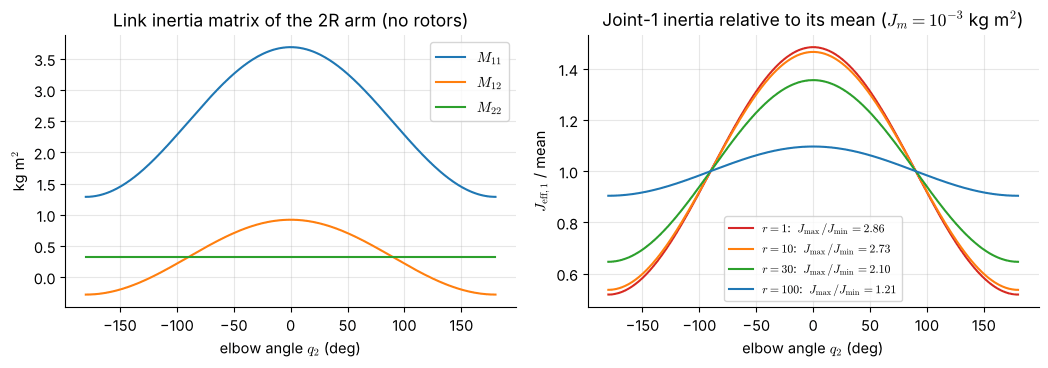

M11 ranges over [1.287, 3.687] kg m^2  (ratio 2.87);  M22 = 0.320 constant


In [8]:
arm = jc.Planar2R()
q2s = np.linspace(-np.pi, np.pi, 361)
M11 = np.array([arm.M_link([0, x])[0, 0] for x in q2s]); M12 = np.array([arm.M_link([0, x])[0, 1] for x in q2s])
M22 = np.array([arm.M_link([0, x])[1, 1] for x in q2s])
Jm_rotor = 1.0e-3

fig, ax = plt.subplots(1, 2, figsize=(10.6, 3.8))
ax[0].plot(np.degrees(q2s), M11, label=r"$M_{11}$"); ax[0].plot(np.degrees(q2s), M12, label=r"$M_{12}$"); ax[0].plot(np.degrees(q2s), M22, label=r"$M_{22}$")
ax[0].set(xlabel=r"elbow angle $q_2$ (deg)", ylabel=r"kg m$^2$", title="Link inertia matrix of the 2R arm (no rotors)"); ax[0].legend()
for r_, c in zip((1, 10, 30, 100), ("C3", "C1", "C2", "C0")):
    Jt = M11 + r_**2 * Jm_rotor
    ax[1].plot(np.degrees(q2s), Jt / Jt.mean(), c, label=f"$r={r_}$:  $J_{{\\max}}/J_{{\\min}}={Jt.max() / Jt.min():.2f}$")
ax[1].set(xlabel=r"elbow angle $q_2$ (deg)", ylabel=r"$J_{\rm eff,1}$ / mean", title=r"Joint-1 inertia relative to its mean ($J_m=10^{-3}$ kg m$^2$)"); ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()
print(f"M11 ranges over [{M11.min():.3f}, {M11.max():.3f}] kg m^2  (ratio {M11.max() / M11.min():.2f});  M22 = {M22[0]:.3f} constant")

An animation makes the effect concrete: as the elbow folds and unfolds the load inertia seen by the shoulder motor
sweeps over a factor of nearly three, but with a high gear ratio the motor "sees" almost no change. (In the live
notebook the animation has play/pause controls; in the saved version a four-frame filmstrip is shown and a GIF is
written to `assets/`.)

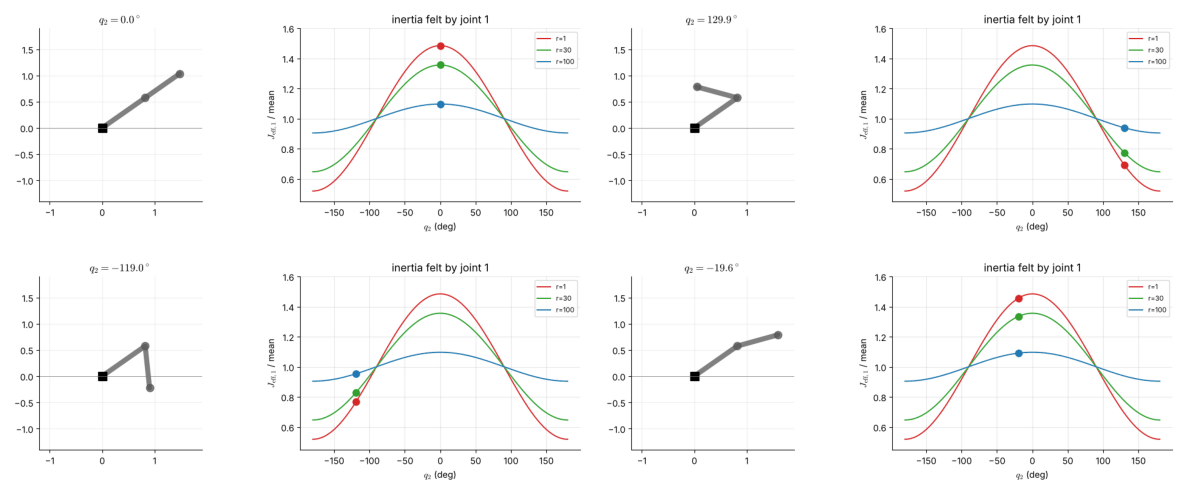

In [9]:
arm = jc.Planar2R()
fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.4, 3.9), gridspec_kw=dict(width_ratios=[1, 1.15]))
fig.subplots_adjust(left=0.06, right=0.98, bottom=0.17, top=0.9, wspace=0.22)
qq2 = np.linspace(-np.pi, np.pi, 361)
M11c = np.array([arm.M_link([0, x])[0, 0] for x in qq2])

def update(s):
    q2 = deg(150) * np.sin(2 * np.pi * s)                    # the elbow swings between -150 and +150 deg
    q = np.array([deg(35), q2])
    elbow, tip = arm.fk(q)
    axa.cla(); axb.cla()
    axa.plot([0, elbow[0], tip[0]], [0, elbow[1], tip[1]], "-o", color="#555", lw=6, ms=9, solid_capstyle="round", alpha=0.75)
    axa.plot([0], [0], "ks", ms=10); axa.axhline(0, color="grey", lw=0.6)
    axa.set(xlim=(-1.2, 1.9), ylim=(-1.4, 1.9), aspect="equal", title=fr"$q_2={np.degrees(q2) + 0.0:6.1f}^\circ$"); axa.grid(alpha=0.2)
    for r_, c in ((1, "C3"), (30, "C2"), (100, "C0")):
        Jt = M11c + r_**2 * Jm_rotor
        axb.plot(np.degrees(qq2), Jt / Jt.mean(), c, lw=1.4, label=f"r={r_}")
        axb.plot([np.degrees(q2)], [(arm.M_link(q)[0, 0] + r_**2 * Jm_rotor) / Jt.mean()], "o", color=c, ms=8)
    axb.set(xlabel=r"$q_2$ (deg)", ylabel=r"$J_{\rm eff,1}$ / mean", ylim=(0.45, 1.6), title="inertia felt by joint 1"); axb.legend(loc="upper right", fontsize=8)

animate(fig, update, np.linspace(0, 1, 48, endpoint=False), interval=70, gif="assets/2.1-inertia-vs-configuration.gif", n_keyframes=4)

**Choosing the gear ratio for a tolerance.** Let $M_{\min}$ and $M_{\max}$ be the extreme link inertias at the joint. The ratio
of effective inertias is $(r^2J_m+M_{\max})/(r^2J_m+M_{\min})$. Requiring it not to exceed $\rho$ gives

$$
r^2J_m \;\ge\; \frac{M_{\max}-\rho\,M_{\min}}{\rho-1}.
$$

For $\rho=1.222$ (i.e. $\pm10\,\%$ about the mean) the course arm with a rotor of $10^{-3}$ kg·m² needs $r\ge98$; this is
Worked Example 2.1.4 below. The interactive explorer lets you vary the rotor inertia and the ratio.

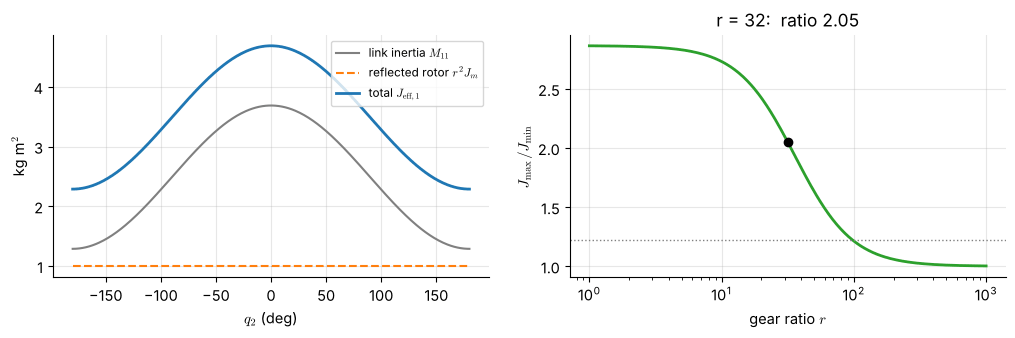

In [10]:
def explore(log10_r=1.5, Jm_rot=1.0e-3):
    r_ = 10 ** log10_r
    Jt = M11 + r_**2 * Jm_rot
    fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.5))
    ax[0].plot(np.degrees(q2s), M11, "grey", label=r"link inertia $M_{11}$"); ax[0].plot(np.degrees(q2s), r_**2 * Jm_rot * np.ones_like(q2s), "C1--", label=r"reflected rotor $r^2J_m$")
    ax[0].plot(np.degrees(q2s), Jt, "C0", lw=2, label=r"total $J_{\rm eff,1}$"); ax[0].set(xlabel=r"$q_2$ (deg)", ylabel="kg m$^2$"); ax[0].legend(fontsize=8.5)
    rr = np.logspace(0, 3, 200); ratio = (M11.max() + rr**2 * Jm_rot) / (M11.min() + rr**2 * Jm_rot)
    ax[1].semilogx(rr, ratio, "C2", lw=2); ax[1].plot([r_], [Jt.max() / Jt.min()], "ko"); ax[1].axhline(1.222, color="grey", ls=":", lw=1)
    ax[1].set(xlabel="gear ratio $r$", ylabel=r"$J_{\max}/J_{\min}$", title=f"r = {r_:.0f}:  ratio {Jt.max() / Jt.min():.2f}")
    plt.tight_layout(); plt.show()

interact(explore, log10_r=widgets.FloatSlider(value=1.5, min=0, max=3, step=0.05, description="log10 r"),
         Jm_rot=widgets.FloatLogSlider(value=1e-3, base=10, min=-5, max=-1, step=0.1, description="J_m (kg m²)", readout_format=".1e"))

## 8. Checking the model against MuJoCo

Before relying on the model we test it against the simulator. We build the same vertical 2R arm in MJCF with
**explicit `<inertial>` elements** (mass, centre-of-mass position and an isotropic inertia tensor whose $zz$-entry is
$I_i$), joint axes along $-\hat y$ so that positive rotation lifts the arm in the $x$–$z$ plane, and give each joint
`armature` $=r_i^2J_{m_i}$ and `damping` $=r_i^2B_{m_i}$ to represent the motors. MuJoCo's `qfrc_bias` is
$C\dot q+g$ and `qfrc_passive` is the (negative of the) viscous torque; the inertia matrix comes from `mj_fullM`.

largest discrepancy over 200 random states:  M 1.8e-15,  g 1.1e-14,  C·qd + g 1.1e-14,  viscous 0.0e+00
tip position from MuJoCo (x, z): [0.6121 1.3463]   from arm.fk: [0.6121 1.3463]


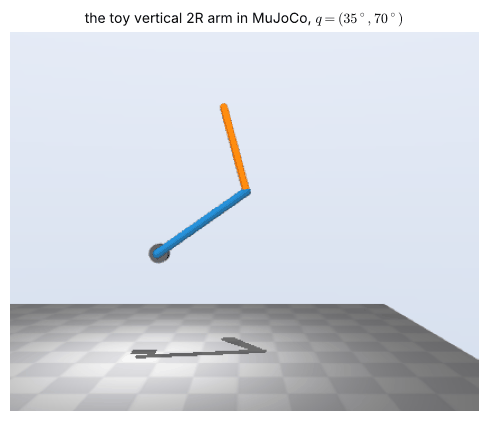

In [11]:
arm = jc.Planar2R(Jm=(2e-3, 1e-3), r=(30.0, 20.0), Bm=(1e-3, 2e-3))

def toy_2r_xml(a, floor_z=-1.0):
    cap = lambda l, rad, rgba: f'<geom type="capsule" fromto="0 0 0 {l} 0 0" size="{rad}" rgba="{rgba}" contype="0" conaffinity="0"/>'
    return f"""
<mujoco model="toy 2R">
  <option gravity="0 0 -9.81" integrator="RK4" timestep="0.0005"/>
  {mju.scene_assets()}
  <worldbody>
    {mju.floor(z=floor_z, size=3)}
    <geom type="cylinder" pos="0 0.12 0" euler="90 0 0" size="0.09 0.05" rgba="0.3 0.3 0.35 1" contype="0" conaffinity="0"/>
    <body name="link1">
      <joint name="q1" axis="0 -1 0" armature="{a.r[0]**2 * a.Jm[0]}" damping="{a.r[0]**2 * a.Bm[0]}"/>
      <inertial pos="{a.lc1} 0 0" mass="{a.m1}" diaginertia="{a.I1} {a.I1} {a.I1}"/>
      {cap(a.l1, 0.04, '0.12 0.47 0.71 1')}
      <body name="link2" pos="{a.l1} 0 0">
        <joint name="q2" axis="0 -1 0" armature="{a.r[1]**2 * a.Jm[1]}" damping="{a.r[1]**2 * a.Bm[1]}"/>
        <inertial pos="{a.lc2} 0 0" mass="{a.m2}" diaginertia="{a.I2} {a.I2} {a.I2}"/>
        {cap(a.l2, 0.035, '1.0 0.5 0.05 1')}
        <site name="tip" pos="{a.l2} 0 0" size="0.03" rgba="0.84 0.15 0.16 1"/>
      </body>
    </body>
  </worldbody>
</mujoco>"""

model2r, data2r = mju.load(toy_2r_xml(arm))
rng = np.random.default_rng(7)
err_M = err_g = err_b = err_p = 0.0
for _ in range(200):
    q_, dq_ = rng.uniform(-3, 3, 2), rng.uniform(-3, 3, 2)
    data2r.qpos[:], data2r.qvel[:] = q_, dq_
    mujoco.mj_forward(model2r, data2r)
    err_M = max(err_M, np.abs(jc.mj_mass_matrix(model2r, data2r) - arm.M(q_)).max())
    err_g = max(err_g, np.abs(jc.mj_gravity(model2r, data2r, q_) - arm.gvec(q_)).max())
    err_b = max(err_b, np.abs(data2r.qfrc_bias - (arm.C(q_, dq_) @ dq_ + arm.gvec(q_))).max())
    err_p = max(err_p, np.abs(-data2r.qfrc_passive - arm.friction(dq_)).max())
print(f"largest discrepancy over 200 random states:  M {err_M:.1e},  g {err_g:.1e},  C·qd + g {err_b:.1e},  viscous {err_p:.1e}")
assert max(err_M, err_g, err_b, err_p) < 1e-9

data2r.qpos[:], data2r.qvel[:] = [deg(35), deg(70)], 0
mujoco.mj_forward(model2r, data2r)
tip = data2r.site("tip").xpos
print("tip position from MuJoCo (x, z):", tip[[0, 2]].round(4), "  from arm.fk:", arm.fk([deg(35), deg(70)])[1].round(4))
img = mju.render(model2r, data2r, camera=dict(azimuth=90, elevation=0, distance=4.2, lookat=(0.8, 0, 0.3)), width=420, height=340)
filmstrip([img], ["the toy vertical 2R arm in MuJoCo, $q=(35^\\circ,70^\\circ)$"], width=5)

The hand-derived $M(q)$, $g(q)$, $C\dot q$ and the viscous torque agree with MuJoCo to rounding error — including the
reflected rotor inertia, which MuJoCo applies as `armature` on the diagonal. The model is therefore a faithful
description of what the simulator does, and the results of the next notebooks, computed with
`Planar2R`, can be trusted to transfer.

## 9. Real robots: the inertia of every joint of a UR5e and a Panda

How strongly does the effective inertia of a *real* arm depend on its posture? We sample 3000 random configurations
inside the joint limits of the UR5e and of the Franka Panda (both from MuJoCo Menagerie) and record each diagonal
entry $M_{ii}(q)$, which is exactly $J_{{\rm eff},i}$ in the load-side sense of Section 6 (it already contains the
rotor term `armature` $=r_i^2J_{m_i}$). The result is a one-page summary of how "constant" each joint of each arm is.

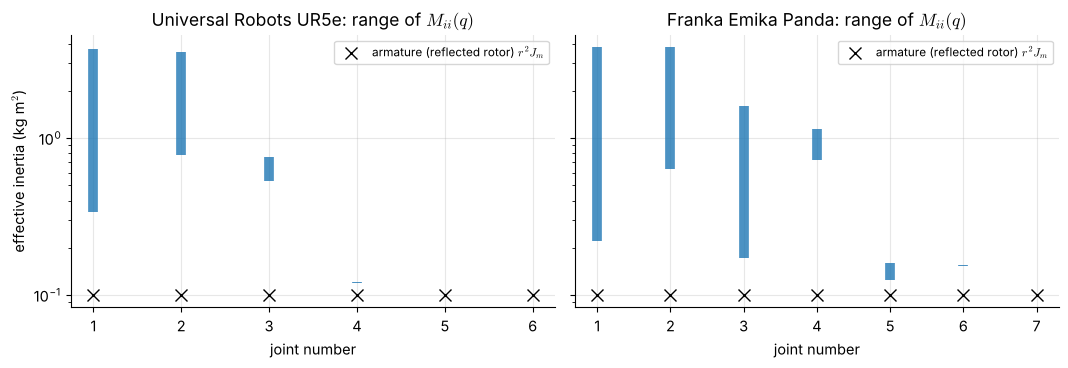

ur5e   min M_ii: [0.337 0.777 0.531 0.119 0.103 0.1  ] 
       max M_ii: [3.722 3.523 0.754 0.12  0.103 0.1  ] 
       ratio   : [11.   4.5  1.4  1.   1.   1. ]
panda  min M_ii: [0.222 0.632 0.173 0.729 0.125 0.152 0.107] 
       max M_ii: [3.796 3.789 1.602 1.14  0.159 0.155 0.107] 
       ratio   : [17.1  6.   9.3  1.6  1.3  1.   1. ]


In [12]:
def inertia_ranges(name, n_samples=3000, seed=0):
    model, data = robots.load_robot(name, scene="bare")
    n = robots.ROBOTS[name]["dof"]
    lo, hi = model.jnt_range[:n, 0], model.jnt_range[:n, 1]
    rng = np.random.default_rng(seed)
    D = np.empty((n_samples, n))
    for k in range(n_samples):
        data.qpos[:n] = rng.uniform(lo, hi)
        mujoco.mj_forward(model, data)
        D[k] = np.diag(jc.mj_mass_matrix(model, data))[:n]
    return model, D

fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.8), sharey=True)
ranges = {}
for ax, name in zip(axes, ("ur5e", "panda")):
    model_, D = inertia_ranges(name)
    n = D.shape[1]; ranges[name] = (model_.dof_armature[:n].copy(), D.min(0), D.max(0))
    ax.vlines(np.arange(1, n + 1), D.min(0), D.max(0), color="C0", lw=7, alpha=0.8)
    ax.plot(np.arange(1, n + 1), model_.dof_armature[:n], "kx", ms=8, label=r"armature (reflected rotor) $r^2J_m$")
    ax.set_yscale("log"); ax.set_xlabel("joint number"); ax.set_xticks(range(1, n + 1))
    ax.set_title(f"{robots.ROBOTS[name]['title']}: range of $M_{{ii}}(q)$"); ax.legend(fontsize=8.5)
axes[0].set_ylabel(r"effective inertia (kg m$^2$)")
plt.tight_layout(); plt.show()
for name in ("ur5e", "panda"):
    arm_, lo_, hi_ = ranges[name]
    print(f"{name:6s} min M_ii:", lo_.round(3), "\n       max M_ii:", hi_.round(3), "\n       ratio   :", (hi_ / lo_).round(1))

The pattern is the one the theory predicts. The first joints carry the weight and the inertia of the whole arm, and
their effective inertia varies by factors of 4.5 to 17 (UR5e: 11 and 4.5 for the base and the shoulder; Panda: 17, 6 and 9
for the first three joints). The wrist joints are dominated by their reflected rotor inertia (the black crosses) and are
practically constant — a ratio of $1.0$ for the three wrist joints of the UR5e and between $1.0$ and $1.6$ for the last four of the Panda.
This is why a controller for a wrist joint is easy to design, and why the **base and shoulder** are where independent-joint control is stressed.

The next cell confirms the claim that `armature` is simply added to the diagonal of $M$, and renders the two UR5e
postures used throughout the chapter: an **extended** arm (horizontal, fully stretched) and a **folded** arm (upper arm
vertical, forearm folded down alongside it).

M with armature - M without armature = armature on the diagonal: True
extended : diag M = [3.743 3.524 0.752 0.119 0.103 0.1  ]
folded   : diag M = [0.415 0.856 0.752 0.119 0.103 0.1  ]
joint 1 (shoulder pan):  9.0x larger inertia when extended  ->  at fixed gains omega_n and zeta change by 1/sqrt = 0.33


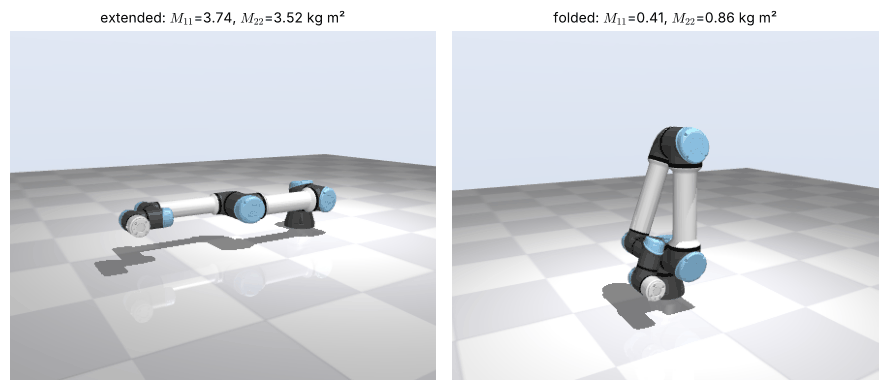

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


In [13]:
model_u, data_u = robots.load_robot("ur5e")                          # the light scene: robot + floor
n = 6
q_ext = np.array([0.0, 0.0, 0.0, -np.pi / 2, 0.0, 0.0])           # arm stretched out horizontally
q_fold = np.array([0.0, -np.pi / 2, 2.8, -np.pi / 2, 0.0, 0.0])   # upper arm vertical, forearm folded down
rows = {}
for label, q_ in (("extended", q_ext), ("folded", q_fold)):
    data_u.qpos[:n] = q_; mujoco.mj_forward(model_u, data_u)
    rows[label] = np.diag(jc.mj_mass_matrix(model_u, data_u))[:n].copy()
    if label == "extended":
        M_with = jc.mj_mass_matrix(model_u, data_u)[:n, :n].copy()
# remove the armature and compare
arm_save = model_u.dof_armature.copy(); model_u.dof_armature[:] = 0.0
mujoco.mj_forward(model_u, data_u); data_u.qpos[:n] = q_ext; mujoco.mj_forward(model_u, data_u)
M_without = jc.mj_mass_matrix(model_u, data_u)[:n, :n].copy()
model_u.dof_armature[:] = arm_save
print("M with armature - M without armature = armature on the diagonal:", np.allclose(M_with - M_without, np.diag(arm_save[:n])))
assert np.allclose(M_with - M_without, np.diag(arm_save[:n]))
for k in ("extended", "folded"):
    print(f"{k:9s}: diag M = {rows[k].round(3)}")
print(f"joint 1 (shoulder pan):  {rows['extended'][0] / rows['folded'][0]:.1f}x larger inertia when extended"
      f"  ->  at fixed gains omega_n and zeta change by 1/sqrt = {np.sqrt(rows['folded'][0] / rows['extended'][0]):.2f}")
imgs = []
cams = (dict(azimuth=60, elevation=-12, distance=1.9, lookat=(-0.45, 0, 0.15)), dict(azimuth=60, elevation=-12, distance=1.6, lookat=(0, 0, 0.35)))
for q_, cam_ in zip((q_ext, q_fold), cams):
    data_u.qpos[:n] = q_; mujoco.mj_forward(model_u, data_u)
    imgs.append(mju.render(model_u, data_u, camera=cam_, width=440, height=360))
filmstrip(imgs, [f"extended: $M_{{11}}$={rows['extended'][0]:.2f}, $M_{{22}}$={rows['extended'][1]:.2f} kg m²",
                 f"folded: $M_{{11}}$={rows['folded'][0]:.2f}, $M_{{22}}$={rows['folded'][1]:.2f} kg m²"], width=9)
print(robots.describe("ur5e"))

## 10. Worked examples

**Example 2.1.1 — effective inertia and damping.** A joint is driven by a motor with $J_m=1.2\times10^{-4}$ kg·m² and
$B_m=2\times10^{-5}$ N·m·s/rad through a $r=60$ reduction. The link has $J_l=0.45$ kg·m² and $B_l=0.9$ N·m·s/rad (joint side).
Find $J_{\rm eff}$ and $B_{\rm eff}$ at the motor and at the load.

*Solution.* Motor side: $J_{\rm eff}=1.2\times10^{-4}+0.45/3600=2.45\times10^{-4}$ kg·m², so the load contributes about as much as
the rotor itself; $B_{\rm eff}=2\times10^{-5}+0.9/3600=2.7\times10^{-4}$ N·m·s/rad. Load side: $J=0.45+3600\cdot1.2\times10^{-4}=0.882$ kg·m²
and $B=0.9+3600\cdot2\times10^{-5}=0.972$ N·m·s/rad — exactly $r^2=3600$ times the motor-side values.

**Example 2.1.2 — the inertia-matching ratio.** For the same motor and load, find the ratio that maximises the load
acceleration for a given motor torque, and compare it with $r=60$, $r=1$ and $r=200$ at $\tau_m=0.3$ N·m.

*Solution.* $r^\star=\sqrt{J_l/J_m}=\sqrt{0.45/1.2\times10^{-4}}=61.2$. The acceleration $r\tau_m/(r^2J_m+J_l)$ is $20.4$ rad/s² at
$r^\star$, $20.4$ rad/s² at $r=60$ (the maximum is flat), $0.666$ rad/s² at $r=1$ and $11.4$ rad/s² at $r=200$. The ratio $60$ chosen
above is therefore a near-optimal one.

**Example 2.1.3 — a voltage-driven motor.** A motor with $R=1.2\,\Omega$, $K_t=K_b=0.05$, $J_m=1.2\times10^{-4}$ kg·m²,
$B_m=2\times10^{-5}$ N·m·s/rad is driven by a constant 24 V with no load. Find the damping, the mechanical time constant and the
no-load speed.

*Solution.* $B_{\rm eff}=B_m+K_tK_b/R=2\times10^{-5}+0.05^2/1.2=2.10\times10^{-3}$ N·m·s/rad (the electrical damping is
$100\times$ the friction). $T_{\rm mech}=J_m/B_{\rm eff}=57.1$ ms. The no-load speed is $(K_t/R)V/B_{\rm eff}=475$ rad/s, slightly below
the ideal $V/K_b=480$ rad/s because of the small viscous friction.

**Example 2.1.4 — choosing the ratio for $\pm10\,\%$ inertia.** For the course arm ($m_1=2$, $m_2=1.5$ kg, $l_1=1$, $l_2=0.8$ m,
uniform rods) and a rotor of $J_m=10^{-3}$ kg·m², find the smallest ratio such that $J_{{\rm eff},1}$ stays within $\pm10\,\%$ of its mean.

*Solution.* $M_{11}$ ranges over $[1.287,\ 3.687]$ kg·m². Within $\pm10\,\%$ of the mean means $J_{\max}/J_{\min}\le1.1/0.9=1.2222$, so
$r^2J_m\ge(3.687-1.2222\cdot1.287)/0.2222=9.51$ kg·m², i.e. $r\ge97.5$. At $r=98$ the realised ratio is $1.2204$; at $r=97$
it would be $1.2244$.

**Example 2.1.5 — a real arm.** On the UR5e in MuJoCo the shoulder-pan inertia is $M_{11}=3.74$ kg·m² with the arm extended and
$0.415$ kg·m² with the arm folded (Section 9). A PD controller tuned for $\omega_n=20$ rad/s and $\zeta=1$ on the *folded* arm is used
on the extended arm. What are $\omega_n$ and $\zeta$ there, and what overshoot results?

*Solution.* With $J$ nine times larger ($3.743/0.415=9.03$), $\omega_n=20/\sqrt{9.03}=6.66$ rad/s and $\zeta=1/\sqrt{9.03}=0.333$, hence an overshoot of
$100\,e^{-\pi\zeta/\sqrt{1-\zeta^2}}=33\,\%$ — which is also what the MuJoCo step response of Notebook 2.5 shows.

In [14]:
# Example 2.1.1
Jm1, Bm1, Jl1, Bl1, r1 = 1.2e-4, 2e-5, 0.45, 0.9, 60.0
Jm_side, Bm_side = jc.effective_inertia(Jm1, Jl1, r1), jc.effective_damping(Bm1, Bl1, r1)
J_load, B_load = jc.reflected_to_load(Jm1, Jl1, r1), Bl1 + r1**2 * Bm1
print(f"Ex 2.1.1  motor side J = {Jm_side:.3e}, B = {Bm_side:.3e};  load side J = {J_load:.4f}, B = {B_load:.4f}")
assert np.isclose(Jm_side, 2.45e-4) and np.isclose(Bm_side, 2.7e-4) and np.isclose(J_load, 0.882) and np.isclose(B_load, 0.972)
assert np.isclose(J_load, r1**2 * Jm_side) and np.isclose(B_load, r1**2 * Bm_side)

# Example 2.1.2
rs = np.sqrt(Jl1 / Jm1)
acc_f = lambda r_: r_ * 0.3 / (r_**2 * Jm1 + Jl1)
print(f"Ex 2.1.2  r* = {rs:.2f};  accel at r*, 60, 1, 200 = {acc_f(rs):.2f}, {acc_f(60):.2f}, {acc_f(1):.3f}, {acc_f(200):.2f} rad/s^2")
assert np.isclose(rs, 61.24, atol=0.01) and np.isclose(acc_f(rs), 20.41, atol=0.01) and np.isclose(acc_f(60), 20.41, atol=0.01)
assert np.isclose(acc_f(1), 0.6665, atol=1e-3) and np.isclose(acc_f(200), 11.4, atol=0.05)

# Example 2.1.3
Bv = jc.effective_damping(2e-5, 0.0, 1.0, Kt=0.05, Kb=0.05, R=1.2)
Tm = 1.2e-4 / Bv; w0 = (0.05 / 1.2) * 24 / Bv
print(f"Ex 2.1.3  B_eff = {Bv:.3e}, T_mech = {Tm * 1e3:.1f} ms, no-load speed = {w0:.0f} rad/s (ideal V/Kb = {24 / 0.05:.0f})")
assert np.isclose(Bv, 2.1e-3, rtol=2e-3) and np.isclose(Tm * 1e3, 57.1, atol=0.1) and np.isclose(w0, 475.4, atol=0.2)

# Example 2.1.4
arm = jc.Planar2R(); q2g = np.linspace(-np.pi, np.pi, 100001)
M11g = np.array([arm.I1 + arm.I2 + arm.m1 * arm.lc1**2 + arm.m2 * (arm.l1**2 + arm.lc2**2 + 2 * arm.l1 * arm.lc2 * np.cos(x)) for x in q2g[::100]])
Mmin, Mmax = M11g.min(), M11g.max(); rho = 1.1 / 0.9
r_req = np.sqrt((Mmax - rho * Mmin) / (rho - 1) / 1e-3)
ratio_at = lambda r_: (Mmax + r_**2 * 1e-3) / (Mmin + r_**2 * 1e-3)
print(f"Ex 2.1.4  M11 in [{Mmin:.3f}, {Mmax:.3f}];  r >= {r_req:.1f};  ratio at r=98: {ratio_at(98):.4f}, at r=97: {ratio_at(97):.4f}  (limit {rho:.4f})")
assert np.isclose(r_req, 97.5, atol=0.1) and ratio_at(98) < rho < ratio_at(97)

# Example 2.1.5
Je, Jf = rows["extended"][0], rows["folded"][0]
wn_new, z_new = 20.0 / np.sqrt(Je / Jf), 1.0 / np.sqrt(Je / Jf)
print(f"Ex 2.1.5  M11 extended {Je:.3f}, folded {Jf:.3f} (ratio {Je / Jf:.2f});  wn = {wn_new:.2f} rad/s, zeta = {z_new:.3f}, overshoot = {jc.overshoot(z_new):.1f} %")
assert np.isclose(wn_new, 6.66, atol=0.02) and np.isclose(z_new, 0.333, atol=0.002) and np.isclose(jc.overshoot(z_new), 33, atol=0.5)

Ex 2.1.1  motor side J = 2.450e-04, B = 2.700e-04;  load side J = 0.8820, B = 0.9720
Ex 2.1.2  r* = 61.24;  accel at r*, 60, 1, 200 = 20.41, 20.41, 0.666, 11.43 rad/s^2
Ex 2.1.3  B_eff = 2.103e-03, T_mech = 57.1 ms, no-load speed = 475 rad/s (ideal V/Kb = 480)
Ex 2.1.4  M11 in [1.287, 3.687];  r >= 97.5;  ratio at r=98: 1.2204, at r=97: 1.2244  (limit 1.2222)
Ex 2.1.5  M11 extended 3.743, folded 0.415 (ratio 9.03);  wn = 6.66 rad/s, zeta = 0.333, overshoot = 33.0 %


## 11. Summary

| Result | Formula |
|:--|:--|
| DC motor (voltage drive, $L\to0$) | $J_m\ddot\theta_m+(B_m+K_tK_b/R)\dot\theta_m=\tfrac{K_t}{R}v-\tau_g$ |
| Gearing ($\theta_m=r\theta_l$, $\tau_l=r\tau_g$) | motor side $J_{\rm eff}=J_m+J_l/r^2$, $B_{\rm eff}=B_m+B_l/r^2$; load side $J_l+r^2J_m$ |
| Inertia matching | $r^\star=\sqrt{J_l/J_m}$ maximises the load acceleration |
| Single-joint plant | $G(s)=\dfrac{1}{s(J_{\rm eff}s+B_{\rm eff})}$: an integrator plus a mechanical pole at $-B_{\rm eff}/J_{\rm eff}$ |
| Planar 2R arm | $M\ddot q+C\dot q+g=\tau$ with $M_{11},M_{12}$ depending on $\cos q_2$, $M_{22}$ constant |
| Disturbance at the motor, fixed motor motion | coupling $\propto1/r^2$, gravity $\propto1/r$, Coriolis $\propto1/r^3$ |
| Inertia variation | $J_{\max}/J_{\min}=(r^2J_m+M_{\max})/(r^2J_m+M_{\min})\to1$ as $r\to\infty$ |
| Real arms | the first joints' inertia varies by a factor 4.5–17; wrist joints are rotor-dominated and nearly constant |

### Common mistakes

* Using $J_l r^2$ instead of $J_l/r^2$ at the motor shaft (or forgetting that the *rotor* inertia is multiplied by $r^2$ at the load).
* Treating the reduction as lossless when computing torque limits: real gearboxes have efficiency below one and backlash and friction.
* Believing that a high gear ratio makes gravity negligible: it divides gravity by $r$ at the motor, but the controller stiffness also scales, so the *joint-angle* droop is determined by $g/k_p$ in joint coordinates (Notebook 2.2).
* Forgetting that MuJoCo's `armature` is the *load-side* reflected rotor inertia $r^2J_m$, not the motor inertia $J_m$.
* Using a single joint's inertia from a table or a datasheet for a joint whose load inertia depends on the posture (shoulder, elbow).

## Exercises

**2.1.1** Starting from the motor-side equation, show that the load-side inertia is $J_l+r^2J_m$, and that the mechanical time
constant $J/B$ has the same value whether it is computed on the motor side or on the load side, for any $r$, $B_m$ and $B_l$.

<details><summary>Answer</summary>

Multiplying the motor-side equation by $r^2$ and using $\theta_m=r\theta_l$ turns $(J_m+J_l/r^2)\ddot\theta_m$ into $(r^2J_m+J_l)\ddot\theta_l\cdot$ (with torque $r\tau_m$), and similarly for the damping. Both coefficients are multiplied by the *same* factor $r^2$, so $J/B$ is unchanged. Numerically for Example 2.1.1: $2.45\times10^{-4}/2.7\times10^{-4}=0.907$ s and $0.882/0.972=0.907$ s.
</details>

**2.1.2** A motor with $J_m=3.0\times10^{-5}$ kg·m² drives a load $J_l=0.12$ kg·m². (a) Find $r^\star$. (b) With $r=100$ find $J_{\rm eff}$ at the motor and the fraction of it due to the load.

<details><summary>Answer</summary>

(a) $r^\star=\sqrt{0.12/3\times10^{-5}}=63.2$. (b) $J_{\rm eff}=3\times10^{-5}+0.12/10^4=4.2\times10^{-5}$ kg·m²; the load accounts for $0.12/10^4=1.2\times10^{-5}$, i.e. $28.6\,\%$.
</details>

**2.1.3** A voltage-driven motor has $R=2\,\Omega$, $K_t=K_b=0.08$, $J_m=2\times10^{-4}$, $B_m=0$. (a) Find the time constant. (b) By what factor is the time constant reduced if the amplifier is changed to a current drive with the same load? (Hint: what is $B_{\rm eff}$ then?)

<details><summary>Answer</summary>

(a) $B_{\rm eff}=0.08^2/2=3.2\times10^{-3}$, $T=2\times10^{-4}/3.2\times10^{-3}=62.5$ ms. (b) With a current drive and $B_m=0$ there is no damping at all, so the velocity does not settle (the time constant is infinite); the back-EMF damping is the only thing limiting speed in the voltage-driven case. The feedback controller of the next notebook must then supply all the damping.
</details>

**2.1.4** Show that for the 2R arm $\det M(q)=M_{11}M_{22}-M_{12}^2>0$ for all $q_2$, and find the configurations of smallest determinant for the course arm.

<details><summary>Answer</summary>

Write $a=m_2l_1l_{c_2}$, $b=I_2+m_2l_{c_2}^2$ and $c_0=I_1+m_1l_{c_1}^2+m_2l_1^2$. Then $M_{11}=c_0+b+2a\cos q_2$, $M_{12}=b+a\cos q_2$, $M_{22}=b$, and
$\det M=c_0b-a^2\cos^2q_2$. The determinant is smallest when $\cos^2q_2=1$ (arm straight, $q_2=0$ or $\pi$), where it equals
$(I_1+m_1l_{c_1}^2)\,b+m_2l_1^2I_2>0$. For the course arm: $c_0=2.1667$, $b=0.32$, $a=0.6$, so $\det M\in[0.3333,\ 0.6933]$ kg²m⁴.
</details>

**2.1.5** (*Coriolis scaling*) Show that at the motor shaft the Coriolis/centrifugal torque of joint 1 scales as $1/r^3$ for a fixed motor motion.

<details><summary>Answer</summary>

$C\dot q$ is quadratic in the joint velocities, $\dot q=\dot\theta_m/r$, giving a factor $1/r^2$; the torque is divided by $r_1$ on its way to the motor, a further $1/r$. Total $1/r^3$ (verified numerically in Section 6).
</details>

**2.1.6** (*Programming*) Using `jc.Planar2R` with $J_m=10^{-3}$ kg·m², find numerically the smallest integer $r$ for which $J_{\max}/J_{\min}\le1.05$ for joint 1.

<details><summary>Answer</summary>

$r^2J_m\ge(M_{\max}-1.05M_{\min})/0.05=(3.687-1.351)/0.05=46.7$ kg·m² so $r\ge216.1$, i.e. $r=217$.
</details>

**2.1.7** (*MuJoCo*) Load the Panda and find, by random search over its joint range, a configuration with a *small* $M_{33}$ and one with a *large* $M_{33}$. What does the ratio tell you about gains tuned at one of them?

<details><summary>Answer</summary>

With 3000 samples the range of $M_{33}$ is about $0.17$–$1.60$ kg·m² (ratio $\approx9$). Since $\omega_n$ and $\zeta$ both scale as $J^{-1/2}$, gains tuned at the *large* inertia give a natural frequency and damping ratio about three times higher at the small one (a stiff, over-damped loop, which may excite unmodelled dynamics), while gains tuned at the *small* inertia give a natural frequency and a damping ratio three times too low at the large one (a lightly damped, oscillatory loop).
</details>

In [15]:
# ---- Verification of the exercise answers -------------------------------------------------------
# 2.1.1
print("2.1.1:", Jm_side / Bm_side, J_load / B_load); assert np.isclose(Jm_side / Bm_side, J_load / B_load)
# 2.1.2
rs2 = np.sqrt(0.12 / 3e-5); Je2 = jc.effective_inertia(3e-5, 0.12, 100.0)
print(f"2.1.2: r* = {rs2:.1f}; J_eff = {Je2:.2e}; load fraction = {0.12 / 1e4 / Je2:.3f}")
assert np.isclose(rs2, 63.2, atol=0.05) and np.isclose(Je2, 4.2e-5) and np.isclose(0.12 / 1e4 / Je2, 0.2857, atol=1e-3)
# 2.1.3
B3 = 0.08**2 / 2; print(f"2.1.3: B_eff = {B3:.1e}, T = {2e-4 / B3 * 1e3:.1f} ms"); assert np.isclose(2e-4 / B3, 0.0625)
# 2.1.4
arm = jc.Planar2R(); dets = np.array([np.linalg.det(arm.M_link([0, x])) for x in q2g[::100]])
a_, b_, c0_ = arm.m2 * arm.l1 * arm.lc2, arm.I2 + arm.m2 * arm.lc2**2, arm.I1 + arm.m1 * arm.lc1**2 + arm.m2 * arm.l1**2
print(f"2.1.4: det M in [{dets.min():.4f}, {dets.max():.4f}];  closed form c0*b - a^2 = {c0_ * b_ - a_**2:.4f}, c0*b = {c0_ * b_:.4f}  (c0={c0_:.4f}, b={b_:.2f}, a={a_:.2f})")
assert np.isclose(dets.min(), c0_ * b_ - a_**2) and np.isclose(dets.max(), c0_ * b_) and np.isclose(c0_ * b_ - a_**2, 1 / 3)
assert np.isclose(abs(np.cos(q2g[::100][np.argmin(dets)])), 1.0)
# 2.1.6
rr = np.arange(1, 400); ratio6 = (Mmax + rr**2 * 1e-3) / (Mmin + rr**2 * 1e-3)
r6 = rr[np.argmax(ratio6 <= 1.05)]; print("2.1.6: smallest integer r =", r6, " (analytic r >= %.1f)" % np.sqrt((Mmax - 1.05 * Mmin) / 0.05 / 1e-3))
assert r6 == 217
# 2.1.7
_, Dp = inertia_ranges("panda"); print(f"2.1.7: Panda M33 in [{Dp[:, 2].min():.3f}, {Dp[:, 2].max():.3f}], ratio {Dp[:, 2].max() / Dp[:, 2].min():.1f}")
assert 8 < Dp[:, 2].max() / Dp[:, 2].min() < 10

2.1.1: 0.9074074074074073 0.9074074074074074
2.1.2: r* = 63.2; J_eff = 4.20e-05; load fraction = 0.286
2.1.3: B_eff = 3.2e-03, T = 62.5 ms
2.1.4: det M in [0.3333, 0.6933];  closed form c0*b - a^2 = 0.3333, c0*b = 0.6933  (c0=2.1667, b=0.32, a=0.60)
2.1.6: smallest integer r = 217  (analytic r >= 216.1)


2.1.7: Panda M33 in [0.173, 1.602], ratio 9.3


## Further reading and lectures

* Craig, Ch. 9 (modelling and control of a single joint; the manipulator treated as a set of independent servos) and Ch. 6 for the dynamics used in Section 5.
* Spong, Hutchinson & Vidyasagar, 2nd ed., Ch. 8 *Independent Joint Control* — the DC-motor/gear model and its transfer functions are derived there in detail.
* Siciliano et al., Ch. 8 *Motion Control* — decentralised control as the baseline against which centralised schemes are judged.
* Lynch & Park, Ch. 8 (dynamics of open chains) and Ch. 11 (robot control).
* Lectures: [Sapienza *Robotics 2* (A. De Luca), lecture playlist](https://www.youtube.com/playlist?list=PLAQopGWlIcya6LnIF83QlJTqvpYmJXnDm); [NPTEL *Mechanics and Control of Robotic Manipulators* (IIT Palakkad)](https://nptel.ac.in/courses/112106304); Prof. G. C. Nandi, playlist 2, *Mathematical Foundation of Robotics — Execution Level …* (IIIT Allahabad; by title).
* MuJoCo documentation: [actuators](https://mujoco.readthedocs.io/en/stable/XMLreference.html#actuator) and the `armature` attribute of [joints](https://mujoco.readthedocs.io/en/stable/XMLreference.html#body-joint).

---

[Chapter contents](README.md) &nbsp;·&nbsp; [2.2 Set-Point Control: P, PD and PID →](2.2-set-point-control.ipynb)